In [1]:
import os

print("Working directory:", os.getcwd())
print("\nFiles in working directory:")
print(os.listdir())

Working directory: C:\Users\goniy\Downloads\college-xerox-management

Files in working directory:
['.ipynb_checkpoints', 'college-xerox-management', 'customer_segmentation.ipynb', 'Online Retail.xlsx', 'package-lock.json', 'retail_sales_dataset.csv', 'retail_sales_eda.ipynb']


In [2]:
%pip install pandas matplotlib seaborn scikit-learn openpyxl

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.4 MB 5.2 MB/s eta 0:00:02
   ------- -------------------------------- 1.6/8.4 MB 4.8 MB/s eta 0:00:02
   ----------- ---------------------------- 2.4/8.4 MB 4.0 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.4 MB 4.5 MB/s eta 0:00:02
   ----------------------- ---------------- 5.0/8.4 MB 4.9 MB/s eta 0:00:01
   ------------------------------ --------- 6.3/8.4 MB 5.1 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 5.5 MB/s  0:00:01
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   - -------------------------------------- 1.0/37.4 MB 8.9 MB/s eta 0:00:05
   -- ------------------------------------- 2.1/37.4 MB 6.5 MB/s eta 0:00:06
   ---- ----------------------------------- 3.9/37.4 MB 7.1 MB/s eta 0:00:05
   ----- ----------------

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import pandas as pd
import time

start = time.time()

df = pd.read_excel(
    "Online Retail.xlsx",
    engine="openpyxl",
    usecols=[
        "InvoiceNo",
        "InvoiceDate",
        "CustomerID",
        "Quantity",
        "UnitPrice"
    ]
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Loading time:", round(time.time() - start, 2), "seconds")

display(df.head())

Dataset loaded successfully!
Dataset shape: (541909, 5)
Loading time: 101.48 seconds


,InvoiceNo,Quantity,InvoiceDate,UnitPrice,CustomerID
0,536365,6,2010-12-01 08:26:00,2.55,17850.0
1,536365,6,2010-12-01 08:26:00,3.39,17850.0
2,536365,8,2010-12-01 08:26:00,2.75,17850.0
3,536365,6,2010-12-01 08:26:00,3.39,17850.0
4,536365,6,2010-12-01 08:26:00,3.39,17850.0


In [5]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   Quantity     541909 non-null  int64         
 2   InvoiceDate  541909 non-null  datetime64[us]
 3   UnitPrice    541909 non-null  float64       
 4   CustomerID   406829 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), object(1)
memory usage: 20.7+ MB

Missing values:
InvoiceNo           0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
dtype: int64

Duplicate rows:
237175

Statistical summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [6]:
# Keep the original dataset unchanged
df_clean = df.copy()

# 1. Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# 2. Remove transactions without a CustomerID
df_clean = df_clean.dropna(subset=["CustomerID"])

# 3. Remove cancelled invoices
# In this dataset, invoice numbers beginning with C indicate cancellations
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# 4. Keep only positive quantities and unit prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# 5. Calculate transaction revenue
df_clean["TotalAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Missing CustomerIDs:", df_clean["CustomerID"].isnull().sum())
print("Duplicate rows remaining:", df_clean.duplicated().sum())

display(df_clean.head())

Original rows: 541909
Cleaned rows: 247427
Missing CustomerIDs: 0
Duplicate rows remaining: 0


,InvoiceNo,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalAmount
0,536365,6,2010-12-01 08:26:00,2.55,17850.0,15.30
1,536365,6,2010-12-01 08:26:00,3.39,17850.0,20.34
2,536365,8,2010-12-01 08:26:00,2.75,17850.0,22.00
5,536365,2,2010-12-01 08:26:00,7.65,17850.0,15.30
6,536365,6,2010-12-01 08:26:00,4.25,17850.0,25.50


In [7]:
# Set the analysis date to one day after the last transaction
analysis_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM for each customer
rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (analysis_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
).reset_index()

# Display results
print("Number of customers:", rfm["CustomerID"].nunique())
print("\nRFM summary:")
display(rfm.head())

print("\nStatistical summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

Number of customers: 4338

RFM summary:


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,3125.98
2,12348.0,75,4,1399.80
3,12349.0,19,1,1209.49
4,12350.0,310,1,174.20



Statistical summary:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,1533.853512
std,100.014169,7.697998,6988.432429
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,221.825000
50%,51.000000,2.000000,495.930000
75%,142.000000,5.000000,1188.825000
max,374.000000,209.000000,202359.830000


In [8]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Select the three RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Reduce skewness
rfm_log = np.log1p(rfm_features)

# Standardize the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert scaled data back to a DataFrame
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"]
)

print("Scaled dataset shape:", rfm_scaled_df.shape)
print("\nScaled feature means:")
print(rfm_scaled_df.mean().round(3))

print("\nFirst five scaled records:")
display(rfm_scaled_df.head())

Scaled dataset shape: (4338, 3)

Scaled feature means:
Recency     -0.0
Frequency   -0.0
Monetary    -0.0
dtype: float64

First five scaled records:


,Recency,Frequency,Monetary
0,1.461993,-0.955214,4.010258
1,-2.038734,1.074425,1.423725
2,0.373104,0.386304,0.775889
3,-0.623086,-0.955214,0.658089
4,1.424558,-0.955214,-0.901231


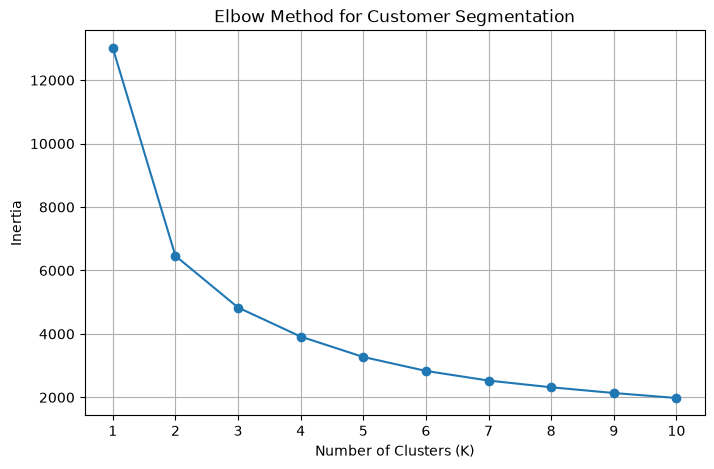

In [9]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(rfm_scaled_df)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [10]:
# Train K-Means with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled_df)

print("Customer count per cluster:")
print(rfm["Cluster"].value_counts().sort_index())

display(rfm.head())

Customer count per cluster:
Cluster
0     879
1     700
2    1171
3    1588
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346.0,326,1,77183.60,2
1,12347.0,2,7,3125.98,1
2,12348.0,75,4,1399.80,2
3,12349.0,19,1,1209.49,0
4,12350.0,310,1,174.20,3


In [11]:
cluster_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

print("Customer segment profiles:")
display(cluster_profile)

Customer segment profiles:


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,879,19.95,2.06,390.00
1,700,11.85,13.87,6194.06
2,1171,68.63,4.19,1340.19
3,1588,185.91,1.33,255.57


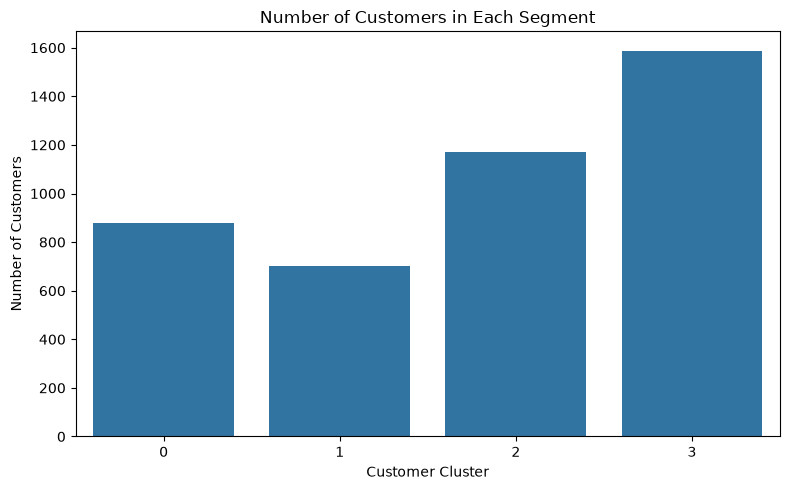

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(data=rfm, x="Cluster")

plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

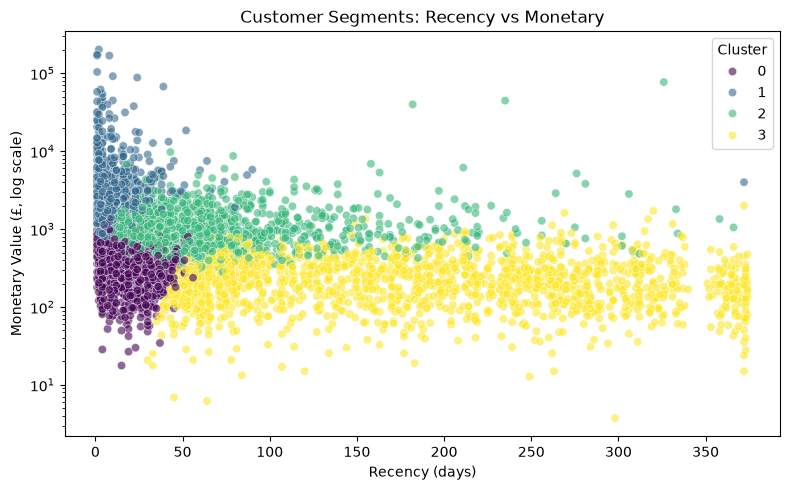

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    alpha=0.6
)

plt.yscale("log")
plt.title("Customer Segments: Recency vs Monetary")
plt.xlabel("Recency (days)")
plt.ylabel("Monetary Value (£, log scale)")
plt.tight_layout()
plt.show()

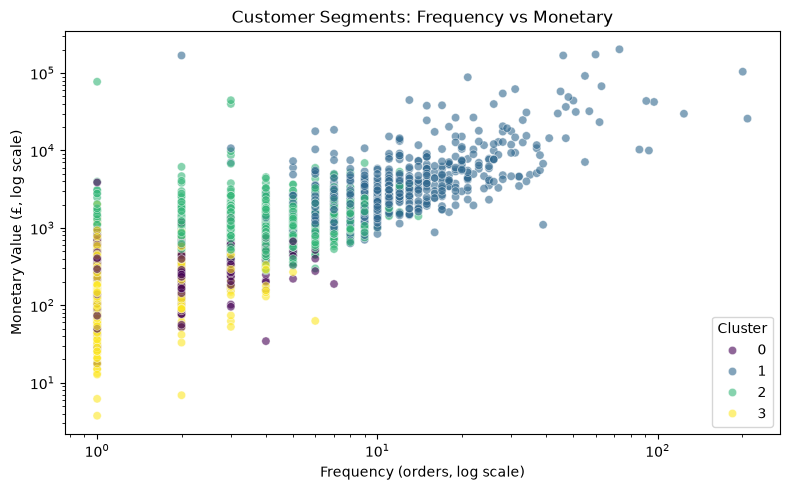

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    alpha=0.6
)

plt.xscale("log")
plt.yscale("log")
plt.title("Customer Segments: Frequency vs Monetary")
plt.xlabel("Frequency (orders, log scale)")
plt.ylabel("Monetary Value (£, log scale)")
plt.tight_layout()
plt.show()

In [ ]:
Segment	Suggested marketing action
Cluster 0 — Recent, low spend	Recommend complementary products and small incentives to encourage a second purchase.
Cluster 1 — High-value loyal customers	Offer loyalty rewards, early access to new products, and personalized recommendations.
Cluster 2 — Moderate-value customers	Send relevant product recommendations and targeted offers to encourage more recent purchases.
Cluster 3 — Inactive, low spend	Test a reactivation email or discount campaign; avoid spending heavily until engagement improves.

These recommendations are based on the RFM averages you calculated. Evaluate campaign results before assuming they will improve sales.

In [15]:
rfm.to_csv("customer_rfm_segments.csv", index=False)
cluster_profile.to_csv("customer_segment_profiles.csv")

print("Saved customer_rfm_segments.csv")
print("Saved customer_segment_profiles.csv")

Saved customer_rfm_segments.csv
Saved customer_segment_profiles.csv


In [18]:
cluster_profile.to_csv("customer_segment_profiles.csv")